# Занятие 3, пара 1. Свёртка и линейные фильтры


Автор ноутбука - Дуркин Анатолий Альбертович

Старший преподаватель кафедры прикладной математики и компьютерных наук СГУ им. Питирима Сорокина

Замечания, предложения, идеи, вопросы, связь с автором:
- anatoliy.durkin@mail.ru
- Telegram - @AnatoDu

Больше информации и материалов на канале автора: https://t.me/code_matan_ai


**Как проходить тетрадь.** Основные примеры работают независимо от заданий «Ваш ход». Если пока пропускаете задание, пропустите и его ячейку `check(...)`; продолжайте со следующего обычного раздела. Упражнения могут использовать ответы предыдущих упражнений. Сохраните свои попытки в отдельной копии тетради.

## Выберите маршрут до запуска

- Если OpenCV установлен: основной разбор ниже, с библиотечной реализацией.
- Если доступны NumPy и Matplotlib: перейдите сразу к разделу [«Самостоятельная работа без OpenCV»](#numpy-route) в конце тетради. Это полноценный вычислительный путь с объяснениями и упражнениями, предыдущие ячейки запускать не нужно.

Выберите **один** маршрут на эту пару. Не запускайте всю тетрадь командой Run All: она содержит два альтернативных пути. Готовые картинки помогают сравнить результат, но не заменяют собственный опыт. Сохраните копию с ответами; GitHub необязателен.


Сегодня попробуем сделать фотографию мягче, а потом резче. Кнопки для этого давно придумали, но хочется понимать, что они делают с числами. Начнём с девяти пикселей — на них прятаться за сложным кодом особенно негде.

К концу пары вы сможете посчитать один результат фильтра, объяснить поведение у края и самостоятельно изменить силу обработки. Понадобятся только арифметика, списки и индексы. Массивы, срезы и цикл здесь повторим.


### Подключим учебные файлы

Следующая ячейка — служебная настройка комплекта. Она находит папку `course_support` у текущей папки или выше и подключает данные и проверки. Её не нужно писать по памяти или менять для задания. `DATA_DIR` — путь к учебным данным, `WORKSPACE_DIR` — корень вашей рабочей папки. `check(номер, ответы)` сравнивает ответ с условиями упражнения, но не выставляет оценку.

Работайте в своей копии и запускайте ячейки сверху вниз. Переменные из другой тетради не нужны. Если поддержку не удалось найти, откройте тетрадь внутри полного комплекта, а не переносите один файл отдельно. Git и интернет для основной работы не нужны.


In [1]:
import sys
from pathlib import Path

# Одинаковый запуск в репозитории курса и в личном проекте.
for WORKSPACE_DIR in (Path.cwd(), *Path.cwd().parents):
    if (WORKSPACE_DIR / 'course_support' / '__init__.py').is_file():
        break
else:
    raise FileNotFoundError('Откройте тетрадь внутри папки с course_support; нужен весь комплект проекта')

# При переключении курса в том же kernel не оставляем чужую поддержку в памяти.
loaded = sys.modules.get('course_support')
expected = WORKSPACE_DIR / 'course_support' / '__init__.py'
if loaded is not None and Path(loaded.__file__).resolve() != expected.resolve():
    for name in list(sys.modules):
        if name == 'course_support' or name.startswith('course_support.'):
            del sys.modules[name]
sys.path.insert(0, str(WORKSPACE_DIR))
from course_support import SUPPORT_DIR, DATA_DIR
COURSE_DIR = SUPPORT_DIR
# Только упражнения о личном README: в репозитории курса это ещё чистый шаблон.
PROJECT_DIR = WORKSPACE_DIR / 'project_template' if (WORKSPACE_DIR / 'project_template').is_dir() else WORKSPACE_DIR
from course_support.checks import check, summary

PROJECT_DIR


PosixPath('/Users/anatoliydurkin/Documents/СГУ/University/Labs/Computer_Vision/project_template')

### Что подключаем

`numpy` хранит изображение как таблицу чисел; короткое имя — `np`. `cv2` — OpenCV, библиотека обработки изображений. `imread`, `imwrite` и `show` — три помощника курса: прочитать файл, сохранить массив как картинку и показать картинку. Они также помогают с русскими буквами в путях. Сейчас достаточно знать их входы и результат; сами фильтры будем разбирать без этих помощников на маленьких массивах.


In [2]:
import numpy as np
import cv2
from course_support.cvtools import imread, imwrite, show


`/` между путём и строкой здесь соединяет папку и имя, а не делит числа. Результаты будем сохранять отдельно от исходных данных. `mkdir` создаёт папку; `parents=True` разрешает создать промежуточные папки, `exist_ok=True` не ругается, если папка уже есть.


In [3]:
OUTPUT_DIR = WORKSPACE_DIR / 'reports' / 'filters'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


Прочитаем фотографию из комплекта. Второй аргумент `cv2.IMREAD_GRAYSCALE` просит одну яркость на пиксель вместо трёх цветовых каналов. `show` принимает массив, а `titles` — список подписей: одна подпись на изображение.


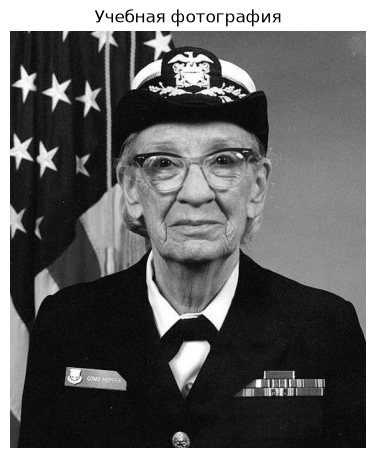

In [4]:
image = imread(DATA_DIR / 'hopper.jpg', cv2.IMREAD_GRAYSCALE)
show(image, titles=['Учебная фотография'])


`shape` сообщает размеры массива: сначала высоту (число строк), потом ширину (число столбцов). `dtype` — тип одного числа. `uint8` хранит целые значения от 0 до 255: 0 — чёрный, 255 — белый. `min()` и `max()` находят крайние значения. Скобки означают вызов действия; у свойств `shape` и `dtype` их нет.


In [5]:
print('Размер:', image.shape)
print('Тип:', image.dtype)
print('Яркости:', image.min(), image.max())


Размер: (600, 512)
Тип: uint8
Яркости: 0 255


Для сравнения у всех возьмём одинаковый небольшой размер. `cv2.resize` получает изображение и **(ширину, высоту)** — порядок обратный `shape`. `interpolation` определяет, как вычислять новые пиксели; `INTER_AREA` усредняет вклад площадей при уменьшении. Сейчас это подготовка фотографии; отдельно изменение размера разберём в 03.2.


In [6]:
image = cv2.resize(image, (256, 300), interpolation=cv2.INTER_AREA)
print(image.shape)


(300, 256)


## Фотография пока подождёт

`np.array` превращает список строк в двумерный массив. Одна внутренняя пара скобок — одна строка. `dtype=np.float64` разрешает хранить дроби: средняя яркость не обязана быть целой. Создадим участок, где один пиксель ярче соседей.


In [7]:
patch = np.array([[10, 10, 10],
                  [10, 90, 10],
                  [10, 10, 10]], dtype=np.float64)
patch


array([[10., 10., 10.],
       [10., 90., 10.],
       [10., 10., 10.]])

В квадратных скобках сначала номер строки, потом столбца. Счёт с нуля: центр нашего массива имеет координаты `[1, 1]`. `shape` здесь должно показать `(3, 3)`. Сначала найдите эти числа глазами.


In [8]:
print(patch.shape)
print(patch[1, 1])


(3, 3)
90.0


### А если яркий пиксель попросить вести себя скромнее?

Возьмём среднее девяти значений. `.sum()` складывает все элементы; `.size` сообщает их количество. Сначала отдельно сумма, затем деление. Должно получиться около 18.89, а не 90. Соседи действительно повлияли на ответ.


In [9]:
total = patch.sum()
count = patch.size
average = total / count
print(total, count, average)


170.0 9 18.88888888888889


Тот же расчёт можно записать иначе: умножить **каждое** число на 1/9, потом сложить. Таблица этих множителей называется **ядром фильтра**. `np.ones((3, 3))` создаёт три строки по три единицы; деление массива на число применяется к каждому элементу.


In [10]:
ones = np.ones((3, 3), dtype=np.float64)
print(ones)
box_kernel = ones / 9
print(box_kernel)


[[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]
[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


Знак `*` между двумя NumPy-массивами одинаковой формы умножает соответствующие элементы. Это не матричное умножение. Смотрим на девять произведений, а уже потом складываем. Второй раз на 9 делить не нужно: деление уже спрятано в весах.


In [11]:
weighted = patch * box_kernel
print(weighted)
print(weighted.sum())


[[ 1.11111111  1.11111111  1.11111111]
 [ 1.11111111 10.          1.11111111]
 [ 1.11111111  1.11111111  1.11111111]]
18.88888888888889


А можно вообще не менять центральное число? Можно: вес центра 1, остальных 0. Для этого пригодится `np.zeros` — такой же конструктор, как `ones`, только с нулями. Присваивание через индекс меняет один элемент. Пробный массив ниже не фильтр: потренируем само присваивание.


In [12]:
test_array = np.zeros((2, 2))
test_array[0, 1] = 7
print(test_array)


[[0. 7.]
 [0. 0.]]


### ✏️ Ваш ход — один новый пиксель

Посчитайте `center_value` через произведение `patch` и `box_kernel`, затем сумму. Создайте `identity_kernel` размером 3×3, чтобы при такой же операции вернулось только значение центра. Покажите результат обоих ядер. Почему первое уменьшает 90, а второе сохраняет?

Подсказка: сначала нулевой массив, затем одна запись по индексу.


In [ ]:
# ✏️ ваш код здесь


In [ ]:
check('03.1.1', center_value, identity_kernel)


**Мой вывод:** замените эту строку своим объяснением результата. Назовите конкретное число, поле или участок изображения, на который опираетесь.


### Можно остановиться здесь

Сохраните тетрадь. Уже можем объяснить, как девять соседей превратились в одно число. При продолжении начните с этой мысли, а не с повторного чтения всей тетради.


## Но на фотографии пикселей больше девяти

Давайте возьмём поле 5×5. Пока запишем числа явно. Это неэффективно для миллиона пикселей, зато каждый из 25 сейчас можно проверить глазами.


In [13]:
small = np.array([[0, 1, 2, 3, 4],
                  [5, 6, 7, 8, 9],
                  [10, 11, 12, 13, 14],
                  [15, 16, 17, 18, 19],
                  [20, 21, 22, 23, 24]], dtype=np.float64)
small


array([[ 0.,  1.,  2.,  3.,  4.],
       [ 5.,  6.,  7.,  8.,  9.],
       [10., 11., 12., 13., 14.],
       [15., 16., 17., 18., 19.],
       [20., 21., 22., 23., 24.]])

Срез `[начало:конец]` берёт несколько элементов, не включая конец. В двумерном массиве задаём срез строк, затем столбцов. Для центра `[1, 1]` нужны строки 0, 1, 2 и такие же столбцы. Сначала выпишете эти девять чисел на бумаге?


In [14]:
region = small[0:3, 0:3]
print(region)
weighted_region = region * box_kernel
print(weighted_region.sum())


[[ 0.  1.  2.]
 [ 5.  6.  7.]
 [10. 11. 12.]]
5.999999999999999


Хотим соседний результат — центр `[1, 2]`. Строки оставим, столбцы сдвинем на один. Ожидаем 7 вместо 6. Обработка изображения и есть повторение этого действия для каждого центра.


In [15]:
next_region = small[0:3, 1:4]
print(next_region)
print((next_region * box_kernel).sum())


[[ 1.  2.  3.]
 [ 6.  7.  8.]
 [11. 12. 13.]]
6.999999999999999


### А у края кто соседи?

Слева от первого столбца данных нет. Нужно договориться, чем продолжать изображение. `np.pad` добавляет рамку. Сначала одномерный пример: `mode='reflect'` отражает внутренние значения, не повторяя крайний элемент. У ряда 10, 20, 30 появятся соседи 20 слева и 20 справа. Это наше соглашение, не найденные за кадром данные.


In [16]:
line = np.array([10, 20, 30])
print(np.pad(line, 1, mode='reflect'))


[20 10 20 30 20]


Для изображения толщина рамки тоже будет 1: ядру 3×3 нужен один сосед с каждой стороны. После добавления рамки старый пиксель `[0, 0]` окажется в позиции `[1, 1]`. Покажем его полное окно.


In [17]:
padded = np.pad(small, 1, mode='reflect')
print(padded)
print(padded[0:3, 0:3])


[[ 6.  5.  6.  7.  8.  9.  8.]
 [ 1.  0.  1.  2.  3.  4.  3.]
 [ 6.  5.  6.  7.  8.  9.  8.]
 [11. 10. 11. 12. 13. 14. 13.]
 [16. 15. 16. 17. 18. 19. 18.]
 [21. 20. 21. 22. 23. 24. 23.]
 [16. 15. 16. 17. 18. 19. 18.]]
[[6. 5. 6.]
 [1. 0. 1.]
 [6. 5. 6.]]


Новые значения положим в отдельный массив. Иначе изменённый пиксель станет соседом для следующего расчёта — получится уже другой алгоритм. `zeros_like(small)` создаёт нулевой массив такой же формы и типа. Запишем результат только в левый верхний угол.


In [18]:
result_demo = np.zeros_like(small)
corner_window = padded[0:3, 0:3]
result_demo[0, 0] = (corner_window * box_kernel).sum()
print(result_demo)


[[4. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]


### Повторение без копирования двадцати пяти ячеек

`for` повторяет строки с отступом. `range(2)` даёт 0 и 1. Вложенный цикл перебирает все столбцы одной строки, потом переходит на следующую. Проверим порядок на четырёх парах координат.


In [19]:
for y in range(2):
    for x in range(2):
        print('строка', y, 'столбец', x)


строка 0 столбец 0
строка 0 столбец 1
строка 1 столбец 0
строка 1 столбец 1


Теперь объединим **уже проделанные** действия в функцию `manual_filter`. `def` объявляет функцию, параметры `source_image` и `kernel` получат значения при вызове, `return` вернёт результат.

1. `.astype(np.float64)` создаёт копию с дробными числами.
2. `height, width = image.shape` раскладывает два размера по двум переменным.
3. Добавляем рамку, создаём пустой результат.
4. Циклами перебираем центры, выбираем окно, умножаем и суммируем.

Для учебной функции ограничимся ядрами **3×3**. Проверка формы с `!=` означает «не равно», `raise ValueError` останавливает вызов с понятной причиной. Универсальный конструктор фильтров сейчас только отвлёк бы нас.


In [20]:
def manual_filter(source_image, kernel: np.array = box_kernel) -> np.array:
    """Functions
    :param kernel: hghgrjgjrgkr
    :return: jvjrhghr
    """
    if kernel.shape != (3, 3):
        raise ValueError('Учебная функция принимает ядро 3×3')
    work = source_image.astype(np.float64)
    height, width = work.shape
    padded = np.pad(work, 1, mode='reflect')
    result = np.zeros_like(work)
    for y in range(height):
        for x in range(width):
            region = padded[y:y + 3, x:x + 3]
            products = region * kernel
            result[y, x] = products.sum()
    return result

manual_demo = manual_filter(small, box_kernel)
print(manual_demo)


[[ 4.          4.33333333  5.33333333  6.33333333  6.66666667]
 [ 5.66666667  6.          7.          8.          8.33333333]
 [10.66666667 11.         12.         13.         13.33333333]
 [15.66666667 16.         17.         18.         18.33333333]
 [17.33333333 17.66666667 18.66666667 19.66666667 20.        ]]


## Передадим знакомую работу OpenCV

`cv2.filter2D(изображение, тип_результата, ядро, borderType=...)` выполняет тот же проход значительно быстрее Python-цикла. `cv2.CV_64F` просит дробный результат. `cv2.BORDER_REFLECT_101` — то же отражение, которое мы задали через `np.pad`.

Первую проверку сделаем ядром, которое ничего не меняет. Если программа вернула другое поле — сначала разберёмся с этим простым случаем.


In [22]:
identity_kernel = np.zeros((3,3))
identity_kernel[1,1] = 1

In [ ]:
# Отдельное ядро демонстрации: ответ identity_kernel не требуется.
demo_identity_kernel = np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]], dtype=float)

In [23]:
identity_result = cv2.filter2D(small, cv2.CV_64F, demo_identity_kernel,
                               borderType=cv2.BORDER_REFLECT_101)
print(identity_result)


[[ 0.  1.  2.  3.  4.]
 [ 5.  6.  7.  8.  9.]
 [10. 11. 12. 13. 14.]
 [15. 16. 17. 18. 19.]
 [20. 21. 22. 23. 24.]]


Как сравнивать таблицы чисел? Вычтем их поэлементно. `np.abs` убирает знак каждой разницы, `.max()` выбирает наибольшую. Около 10⁻¹⁴ — обычная погрешность дробной арифметики; это не заметная ошибка яркости. Для начала пример с явно отличающимися числами.


In [24]:
difference_demo = np.array([10.0, 12.0]) - np.array([9.0, 14.0])
print(difference_demo)
absolute_demo = np.abs(difference_demo)
print(absolute_demo.max())


[ 1. -2.]
2.0


### ✏️ Ваш ход — сверяем свой расчёт с библиотекой

Примените к `small` ядро `box_kernel` двумя способами. Сохраните `manual_result` и `opencv_result`. Найдите максимальную абсолютную разницу по образцу выше. Не округляйте массивы перед сравнением. Объясните, почему важно одинаково продолжить край.


In [ ]:
# ✏️ ваш код здесь


In [ ]:
check('03.1.2', manual_result, opencv_result)


**Мой вывод:** замените эту строку своим объяснением результата. Назовите конкретное число, поле или участок изображения, на который опираетесь.


Точность названия: `filter2D` не переворачивает ядро. Математически это корреляция. У симметричных ядер этой пары результат совпадает со свёрткой, для которой ядро переворачивают. Сейчас важно, что мы сравниваем одну и ту же операцию.


### Пора вернуться к фотографии

Сначала переведём её в дробные числа, как маленькое поле. Усреднение 3×3 уже знакомо. Посмотрите на глаза, текст и границу одежды: что стало менее различимым?

Для показа среднего вернём uint8 отдельным astype: значения после усреднения уже в диапазоне0…255. Дробную версию сохраняем для расчётов. Так show использует одинаковую шкалу0…255, а не растягивает контраст каждой картинки отдельно.


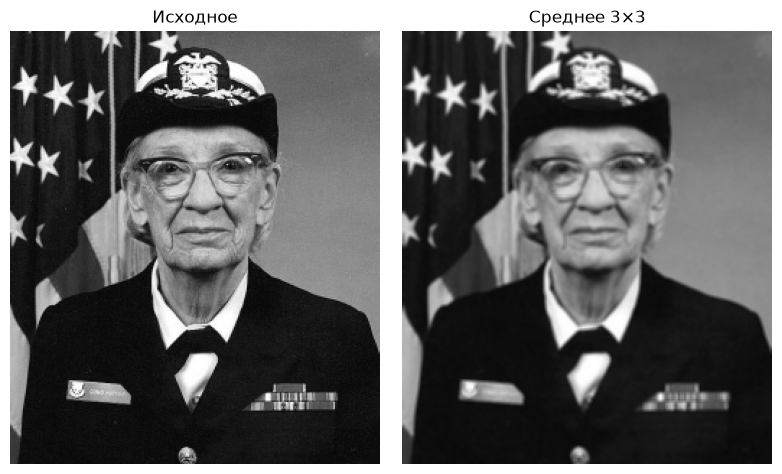

In [25]:
image_float = image.astype(np.float64)
blur3 = cv2.filter2D(image_float, -1, box_kernel,
                     borderType=cv2.BORDER_REFLECT_101)
# -1 оставляет тип входного массива, здесь float64.
blur3_picture = blur3.astype(np.uint8)
show(image, blur3_picture, titles=['Исходное', 'Среднее 3×3'])


Хотим размытие сильнее — возьмём более широкое окно. В ядре 9×9 уже 81 сосед, поэтому делим на 81. Меняем только размер окна; фотография остаётся прежней.


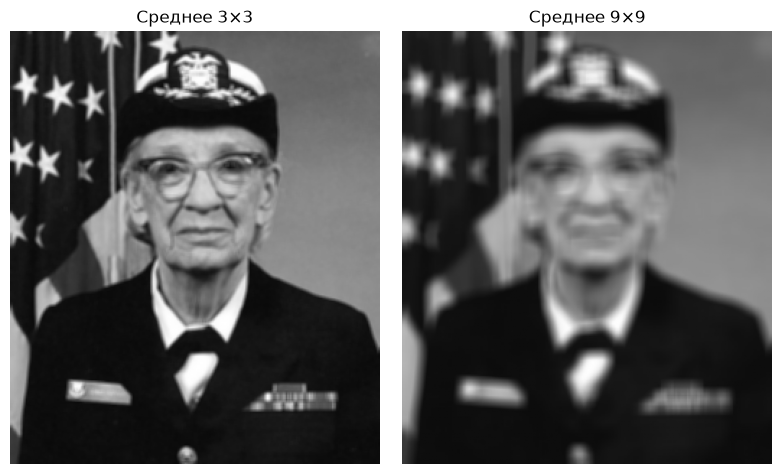

In [26]:
large_kernel = np.ones((9, 9)) / 81
blur9 = cv2.filter2D(image_float, -1, large_kernel,
                     borderType=cv2.BORDER_REFLECT_101)
blur9_picture = blur9.astype(np.uint8)
show(blur3_picture, blur9_picture, titles=['Среднее 3×3', 'Среднее 9×9'])


## А теперь резче

У этого ядра центр получает вес 5, четыре соседа — минус 1. На ровном участке итог не меняется: 5−1−1−1−1=1. Если центр отличается от соседей, отличие усилится. Это подчёркивает границы, но может усилить и шум. Сначала применим к нашим девяти числам.

`dtype=float` — запись дробного типа Python, в этом примере соответствует используемому float64.


In [27]:
sharp_demo = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float)
print(sharp_demo.sum())
print((patch * sharp_demo).sum())


1.0
410.0


Получилось 410 — больше допустимых 255. Фильтр не обязан следить за диапазоном картинки. `np.clip(массив, минимум, максимум)` ограничивает числа. `.astype(np.uint8)` затем превращает их в целые пиксели. Важно делать именно в этом порядке: простое преобразование типа не заменяет ограничение.


In [28]:
values_demo = np.array([-10.0, 10.7, 410.0])
limited_demo = np.clip(values_demo, 0, 255)
print(limited_demo)
print(limited_demo.astype(np.uint8))


[  0.   10.7 255. ]
[  0  10 255]


### ✏️ Ваш ход — регулируем резкость

Вместо силы 1 возьмём `a=0.5`. Четыре соседа получают `-a`, центр — `1 + 4*a`, углы — 0. Создайте `sharp_kernel`, примените его к `image_float`, сохраните дробный `sharp_result`. Для показа отдельно выполните `clip` и `astype`.

После проверки в новой ячейке попробуйте a=0 и a=1. Укажите участок, где усиление помогает, и участок, где мешает.


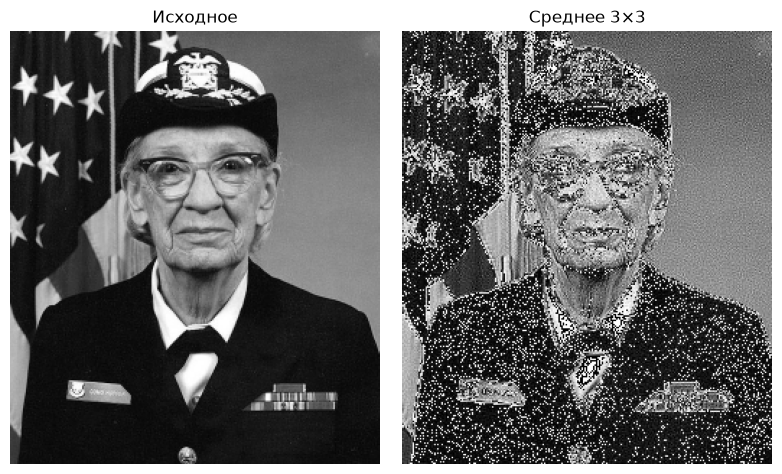

In [29]:
# ✏️ ваш код здесь
image_float = image.astype(np.float64)
blur3 = cv2.filter2D(image_float, -1, sharp_demo,
                     borderType=cv2.BORDER_REFLECT_101)
# -1 оставляет тип входного массива, здесь float64.
blur3_picture = blur3.astype(np.uint8)
show(image, blur3_picture, titles=['Исходное', 'Среднее 3×3'])


In [ ]:
check('03.1.3', sharp_kernel, sharp_result, image_float)


**Мой вывод:** замените эту строку своим объяснением результата. Назовите конкретное число, поле или участок изображения, на который опираетесь.


Сохраним именно картинку после ограничения диапазона. `imwrite` принимает путь и массив. PNG сохранит полученные пиксели без дополнительного JPEG-сжатия.


Для сохранения независимо от упражнения применим уже разобранное ядро `sharp_demo`. Сначала считаем дробные значения, затем ограничиваем диапазон для картинки. Ваш `sharp_picture` не меняем.

In [ ]:
demo_sharp = cv2.filter2D(image.astype(np.float64), -1, sharp_demo,
                          borderType=cv2.BORDER_REFLECT_101)
demo_sharp_clipped = np.clip(demo_sharp, 0, 255)
demo_sharp_picture = demo_sharp_clipped.astype(np.uint8)

In [ ]:
result_path = OUTPUT_DIR / 'sharpened.png'
imwrite(result_path, demo_sharp_picture)
print(result_path)


## Если закончили раньше: два опыта на выбор

**1. Граница — тоже решение (8–10 минут).** Создайте `constant = np.ones((7, 7)) * 100`. Примените `filter2D` с ядром 3×3 сначала с `BORDER_REFLECT_101`, затем с `BORDER_CONSTANT`. Второй режим подставляет нули снаружи. Сравните `[0, 0]` и `[3, 3]` численно. Предскажите ответ до запуска: сколько из девяти значений углового окна настоящие? Объясните появление тёмной рамки.

**2. Ближним соседям больше доверия (8–10 минут).** Ниже — гауссово размытие. У него веса уменьшаются с расстоянием от центра. `sigmaX` задаёт ширину весов; для этой настройки по вертикали используется такое же значение. Окно `(9,9)` ограничивает дальность. Попробуйте 0.6, 1.5 и 3 по очереди, меняя одну строку, и найдите момент потери мелкой детали.

Функция `cv2.GaussianBlur` выполняет гауссово сглаживание; ниже ей передаются исходник, окно и sigma.


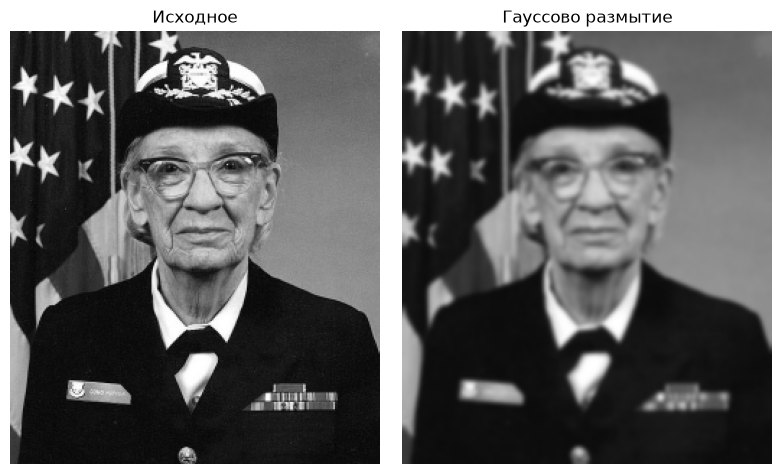

In [30]:
gaussian = cv2.GaussianBlur(image, (9, 9), sigmaX=1.5,
                            borderType=cv2.BORDER_REFLECT_101)
show(image, gaussian, titles=['Исходное', 'Гауссово размытие'])


## Перед закрытием

Сохраните тетрадь и `reports/filters/sharpened.png`, сделайте отдельную копию. Можете ли вы объяснить без кода: что делает ядро, зачем обсуждать край и почему резкость не восстанавливает потерянную информацию? Если нет — вернитесь к маленькому `patch`, а не перечитывайте всю функцию сразу.

Это практика для части ЛР 2 о фильтрации; отдельные баллы за неё не добавляются. В следующей паре испортим фотографию контролируемым шумом и проверим, какой фильтр помогает.

По желанию — [практикум OpenCV по фильтрации](https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html). Начните с одного знакомого примера, весь раздел за вечер читать не требуется.


In [ ]:
summary('03.1')


<a id="numpy-route"></a>
## Самостоятельная работа без OpenCV: NumPy и Matplotlib

Это отдельный маршрут той же пары. Начните **здесь в новом ядре**: предыдущие ячейки OpenCV не нужны. Выполняйте только этот раздел до конца. «Запустить все ячейки» для всей тетради не используем, потому что выше расположен альтернативный маршрут с OpenCV. Для обеих версий результат — ваш опыт, объяснение и сохранённый файл, а не число зелёных галочек.

Здесь нет проверки `03.x.1–3`: она относится к реализации на OpenCV выше. В этом маршруте сверяйте маленькие расчёты с разобранными примерами и объясняйте наблюдения; требования ЛР2 одинаковые. Готовые иллюстрации ниже — только ориентир для обсуждения, не ваш выполненный эксперимент.


`numpy` хранит изображение как массив чисел, `matplotlib.pyplot` показывает его. Сокращения `np` и `plt` просто удобные имена. Данные создадим прямо в тетради; ни интернет, ни соседние тетради не нужны.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt


### 1. Картинка — таблица чисел

`np.array` превращает список строк в двумерный массив. 0 — чёрный, 255 — белый. `dtype=float` разрешает дробные и отрицательные результаты вычислений: окончательный показ и расчёт — разные задачи. `shape` сообщает высоту и ширину. В нашем массиве есть яркий центральный пиксель.


In [ ]:
image = np.array([
    [20, 20, 20, 20, 20],
    [20, 40, 40, 40, 20],
    [20, 40, 220, 40, 20],
    [20, 40, 40, 40, 20],
    [20, 20, 20, 20, 20]
], dtype=float)
print(image.shape)
print(image)


Первый индекс — строка, второй — столбец; счёт от нуля. Срез `[1:4, 1:4]` берёт строки 1,2,3 и столбцы 1,2,3, правые границы не включаются. Это окно вокруг центрального пикселя. `.sum()` складывает все значения, `.size` сообщает число элементов. Разделим сумму на количество — получим среднее.


In [ ]:
patch = image[1:4, 1:4]
print(patch)
total = patch.sum()
count = patch.size
average = total / count
print(total, count, average)


Получается 60 вместо центральных 220: один яркий пиксель разделил свой вклад с восемью соседями. Если это шумовая точка — хорошо. Если это полезная маленькая деталь — мы её испортили. Фильтр не знает, какой случай перед ним.


### ✏️ Ваш ход — новое окно

Для окна со строками `[10,10,10]`, `[10,100,10]`, `[10,10,10]` вычислите `my_average`. Сначала сумму, потом количество и деление. В выводе объясните, почему новый центр не равен 100.


In [ ]:
# ✏️ ваш код здесь


**Мой вывод:** что изменил, что ожидал, что получил и почему. …


### 2. Запишем среднее через веса

`np.ones((3, 3))` создаёт массив из девяти единиц; деление на 9 даёт одинаковые веса 1/9. `patch * kernel` умножает элементы по местам, `.sum()` складывает результат. Именно это действие будем повторять в каждой точке.


In [ ]:
kernel = np.ones((3, 3)) / 9
products = patch * kernel
print(kernel)
print(products)
print(products.sum())


### 3. Что делать у края?

У крайнего пикселя не хватает соседей. `np.pad(image, 1, mode='reflect')` добавляет по одной строке и столбцу с каждой стороны, отражая значения. Размер 5×5 станет 7×7. Теперь окно для исходной точки `(0,0)` находится в `[0:3,0:3]` расширенного массива. Другие правила рамки могут изменить края результата.


In [ ]:
padded = np.pad(image, 1, mode='reflect')
print(padded)
first_patch = padded[0:3, 0:3]
first_products = first_patch * kernel
print('Новый верхний левый пиксель:', first_products.sum())


### 4. Один расчёт повторим много раз

`np.zeros_like` создаёт массив нулей формы исходника. `range(height)` перечисляет номера строк, второй цикл — столбцов. Сначала берём окно, потом произведения, потом сумму. Функция `filter3` получает изображение и ядро 3×3, возвращает новый массив. Исходник не меняется. Мы применяем веса без переворота: технически это корреляция; для симметричного ядра среднего результат совпадает со свёрткой.


In [ ]:
def filter3(source, kernel):
    height, width = source.shape
    padded = np.pad(source, 1, mode='reflect')
    result = np.zeros_like(source, dtype=float)
    for y in range(height):
        for x in range(width):
            patch = padded[y:y+3, x:x+3]
            products = patch * kernel
            result[y, x] = products.sum()
    return result

blurred = filter3(image, kernel)
print(blurred)


`plt.imshow` показывает массив; `cmap='gray'` выбирает серую шкалу. `vmin=0, vmax=255` фиксирует одинаковые границы для всех картинок, `title` добавляет подпись, `show` выводит результат. Не даём каждой картинке растягивать контраст независимо, иначе сравнение будет нечестным.


In [ ]:
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('До фильтра')
plt.show()
plt.imshow(blurred, cmap='gray', vmin=0, vmax=255)
plt.title('После среднего 3×3')
plt.show()


### ✏️ Ваш ход — один изменённый пиксель

Создайте `changed = image.copy()` — независимую копию, присвойте `changed[2,2] = 100`. Предскажите среднее в центре, получите `changed_blur` функцией `filter3`. Покажите обе картинки. Какие выходные пиксели изменились и почему не вся картинка сразу?


In [ ]:
# ✏️ ваш код здесь


**Мой вывод:** что изменил, что ожидал, что получил и почему. …


### 5. Не все веса должны быть одинаковыми

Зададим больше веса центральному пикселю и ближайшим соседям. Все веса ниже складываются в 16, поэтому делим на 16: постоянная яркость останется постоянной. Это маленькое биномиальное сглаживающее ядро, приближающее идею гауссова сглаживания; произвольный вызов GaussianBlur может использовать другие веса.


In [ ]:
weighted_kernel = np.array([[1,2,1],[2,4,2],[1,2,1]], dtype=float) / 16
weighted = filter3(image, weighted_kernel)
print(weighted[2,2])
plt.imshow(weighted, cmap='gray', vmin=0, vmax=255)
plt.title('Центр получил больший вес')
plt.show()


Сглаживание уменьшает перепады. А если хотим их подчеркнуть? Возьмём ядро с отрицательными весами соседей и большим положительным весом центра. Сумма весов 1 сохранит постоянную область, но на границе возможны значения ниже 0 и выше 255. Для расчёта оставляем float; для показа шкала просто не различит значения за диапазоном. Это не восстановление потерянных деталей.


### ✏️ Ваш ход — сравнить размытие и резкость

Примените `sharp_kernel = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]], dtype=float)` к `image`, результат назовите `sharpened`. Выведите `.min()` и `.max()`, покажите в шкале 0…255. Сравните центральный пиксель со средним фильтром. Почему шум усилился? Дополнительно примените ядро к постоянному массиву из 50.


In [ ]:
# ✏️ ваш код здесь


**Мой вывод:** что изменил, что ожидал, что получил и почему. …


Сохранённое сравнение на фотографии из основного маршрута. Это иллюстрация, а не результат вашего запуска. Найдите участок, где усиление резкости подчёркивает полезную границу, и участок, где оно могло усилить мелкие дефекты.

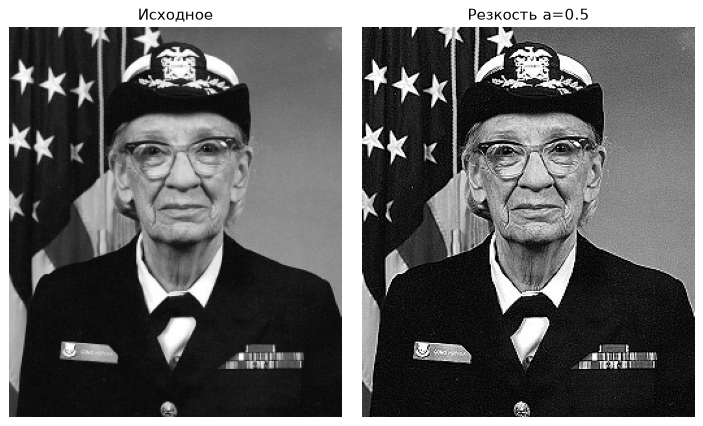


### Сохраняем результат

Сохраните три упражнения, опыты и выводы в своей копии. Вы действительно вычислили фильтр без OpenCV: одно окно → веса → проход по массиву. Для ЛР2 этот способ допустим; следующий маршрут 03.2 добавит одинаковый шум, медиану и численное сравнение. Если захотите проверить библиотечную реализацию позже, вернитесь к основному маршруту в новом ядре.
